# Retail Customer Intelligence & Business Performance Analysis


This notebook explores sales, profit, customers, products, and shipping.

**Tools used:** Pandas and Matplotlib  
This notebook focuses only on data analysis. It does not include machine learning or prediction.


## 1. Import libraries

Pandas helps us work with table data. Matplotlib helps us create charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


## 2. Load the dataset



In [2]:
df = pd.read_csv("store_sales_data.csv")

df.head()


,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Ship Date,Ship Mode,State,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit
0,CUST000001,Curtis,Krause,1973-11-29,3344.69,2023,Large,Tier 1,Fast Food,East,...,2020-04-18,Same Day,West Bengal,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24
1,CUST000002,Jeremy,Foster,1987-08-30,37094.41,2022,Medium,Tier 2,Fast Food,East,...,2021-01-11,Standard Class,Punjab,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34
2,CUST000003,Ariel,Mccann,1980-12-15,35501.08,2023,Large,Village,Electric Appliances,South,...,2020-08-16,Second Class,Gujarat,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21
3,CUST000004,Colleen,Maynard,1989-05-23,8969.33,2021,Medium,Village,Dairy Products,East,...,2021-10-16,First Class,West Bengal,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66
4,CUST000005,Gina,Holden,1957-12-31,35530.44,2021,Small,Village,Sessional Fruits & Vegetables,West,...,2019-01-25,Standard Class,Delhi,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93


## 3. Understand the data

Check the number of rows and columns, column names, and data types.

In [3]:
print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())


Dataset shape: (100000, 25)
Column names:
['Customer ID', 'Customer Name', 'Last Name', 'Date of Birth', 'Sales', 'Year', 'Outlet Type', 'City Type', 'Category of Goods', 'Region', 'Country', 'Segment', 'Sales Date', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'State', 'Postal Code', 'Product ID', 'Sub-Category', 'Product Name', 'Quantity', 'Discount', 'Profit']


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Customer ID        100000 non-null  object 
 1   Customer Name      100000 non-null  object 
 2   Last Name          100000 non-null  object 
 3   Date of Birth      100000 non-null  object 
 4   Sales              100000 non-null  float64
 5   Year               100000 non-null  int64  
 6   Outlet Type        100000 non-null  object 
 7   City Type          100000 non-null  object 
 8   Category of Goods  100000 non-null  object 
 9   Region             100000 non-null  object 
 10  Country            100000 non-null  object 
 11  Segment            100000 non-null  object 
 12  Sales Date         100000 non-null  object 
 13  Order ID           100000 non-null  object 
 14  Order Date         100000 non-null  object 
 15  Ship Date          100000 non-null  object 
 16  Shi

In [5]:
df.head()


,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Ship Date,Ship Mode,State,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit
0,CUST000001,Curtis,Krause,1973-11-29,3344.69,2023,Large,Tier 1,Fast Food,East,...,2020-04-18,Same Day,West Bengal,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24
1,CUST000002,Jeremy,Foster,1987-08-30,37094.41,2022,Medium,Tier 2,Fast Food,East,...,2021-01-11,Standard Class,Punjab,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34
2,CUST000003,Ariel,Mccann,1980-12-15,35501.08,2023,Large,Village,Electric Appliances,South,...,2020-08-16,Second Class,Gujarat,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21
3,CUST000004,Colleen,Maynard,1989-05-23,8969.33,2021,Medium,Village,Dairy Products,East,...,2021-10-16,First Class,West Bengal,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66
4,CUST000005,Gina,Holden,1957-12-31,35530.44,2021,Small,Village,Sessional Fruits & Vegetables,West,...,2019-01-25,Standard Class,Delhi,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93


## 4. Check missing values and duplicates

This helps us understand whether the data needs cleaning.

In [6]:
df.isnull().sum()


Customer ID          0
Customer Name        0
Last Name            0
Date of Birth        0
Sales                0
Year                 0
Outlet Type          0
City Type            0
Category of Goods    0
Region               0
Country              0
Segment              0
Sales Date           0
Order ID             0
Order Date           0
Ship Date            0
Ship Mode            0
State                0
Postal Code          0
Product ID           0
Sub-Category         0
Product Name         0
Quantity             0
Discount             0
Profit               0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


## 5. Basic statistics

View simple statistics for numerical columns such as Sales, Profit, and Quantity.

In [8]:
df.describe()


,Sales,Year,Postal Code,Quantity,Discount,Profit
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,25084.410142,2020.999910,388985.180000,5.493760,0.251320,3755.305114
std,14403.187686,1.413757,184192.704685,2.876102,0.144324,2639.852035
min,100.570000,2019.000000,110001.000000,1.000000,0.000000,6.520000
25%,12618.030000,2020.000000,226001.000000,3.000000,0.130000,1651.105000
50%,25134.695000,2021.000000,380001.000000,5.000000,0.250000,3317.450000
75%,37575.850000,2022.000000,560001.000000,8.000000,0.380000,5363.845000
max,49999.890000,2023.000000,700001.000000,10.000000,0.500000,14563.670000


## 6. Check important columns

These are the main columns used in the analysis. If your dataset uses different names, update the column names in the cells below.

In [9]:
df[["Order Date", "Sales", "Profit", "Quantity", "Discount"]].head()


,Order Date,Sales,Profit,Quantity,Discount
0,2020-04-13,3344.69,448.24,3,0.09
1,2021-01-08,37094.41,3134.34,5,0.39
2,2020-08-11,35501.08,8324.21,6,0.07
3,2021-10-10,8969.33,1962.66,4,0.18
4,2019-01-22,35530.44,2843.93,4,0.27


## 7. Prepare the order date

Convert the order date into a date format so we can group sales by month and year.

In [10]:
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month_name()

df[["Order Date", "Year", "Month"]].head()


,Order Date,Year,Month
0,2020-04-13,2020,April
1,2021-01-08,2021,January
2,2020-08-11,2020,August
3,2021-10-10,2021,October
4,2019-01-22,2019,January


## 8. Total sales and profit

These are two important business measures.

In [11]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))


Total Sales: 2508441014.18
Total Profit: 375530511.43


## 9. Sales by year

Group sales by year and display the result.

In [12]:
yearly_sales = df.groupby("Year")["Sales"].sum().reset_index()

yearly_sales


,Year,Sales
0,2019,5.021777e+08
1,2020,5.007569e+08
2,2021,5.012826e+08
3,2022,5.019531e+08
4,2023,5.022707e+08


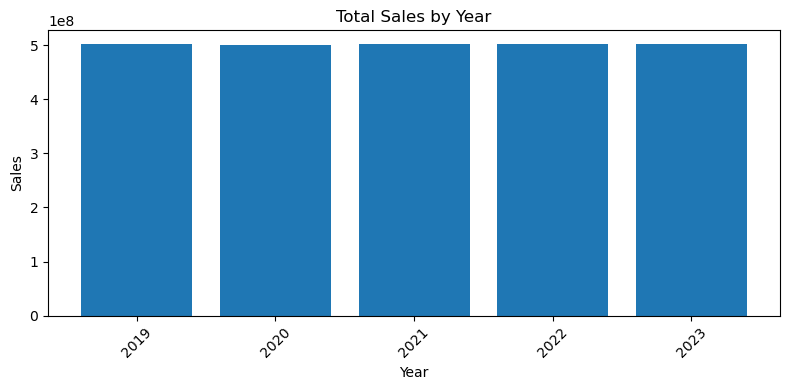

In [13]:
plt.figure(figsize=(8, 4))
plt.bar(yearly_sales["Year"].astype(str), yearly_sales["Sales"])
plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 10. Monthly sales trend

This chart helps us see how sales change over time.

In [14]:
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()

monthly_sales.head()


Order Date
2019-01    42344783.81
2019-02    37865145.00
2019-03    43913954.31
2019-04    40725028.79
2019-05    42081183.23
Freq: M, Name: Sales, dtype: float64

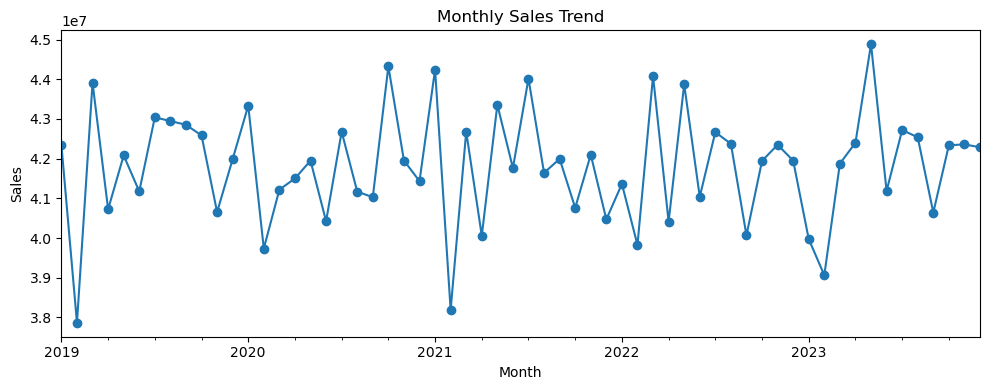

In [15]:
monthly_sales.plot(kind="line", figsize=(10, 4), marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()


## 11. Sales by category

Compare the sales generated by each product category.

In [20]:
category_sales = df.groupby("Category of Goods")["Sales"].sum().sort_values(ascending=False)

category_sales


Category of Goods
Sessional Fruits & Vegetables    4.199427e+08
Household Items                  4.197889e+08
Electric Appliances              4.188296e+08
Dairy Products                   4.180117e+08
Fast Food                        4.178508e+08
Furniture                        4.140173e+08
Name: Sales, dtype: float64

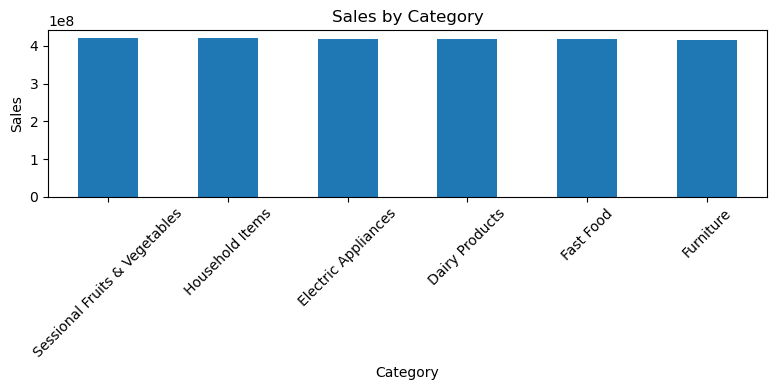

In [21]:
category_sales.plot(kind="bar", figsize=(8, 4))
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 12. Profit by category

Compare the profit earned from each category.

In [23]:
category_profit = df.groupby("Category of Goods")["Profit"].sum().sort_values(ascending=False)

category_profit


Category of Goods
Household Items                  62871293.87
Fast Food                        62787837.10
Sessional Fruits & Vegetables    62766851.82
Electric Appliances              62702992.93
Dairy Products                   62592431.61
Furniture                        61809104.10
Name: Profit, dtype: float64

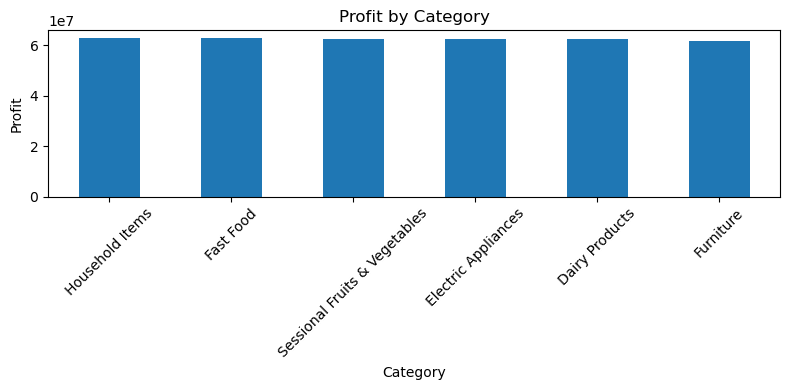

In [24]:
category_profit.plot(kind="bar", figsize=(8, 4))
plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 13. Top 10 products by sales

Find the ten products with the highest total sales.

In [25]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products


Product Name
Beds - 120             467564.82
Refrigerators - 338    463807.16
Butter - 951           458374.84
Mops - 693             418713.15
Burgers - 729          408224.56
Fans - 611             402263.31
Mangoes - 912          402158.97
Apples - 425           379721.59
Milk - 660             373800.17
Refrigerators - 709    373166.48
Name: Sales, dtype: float64

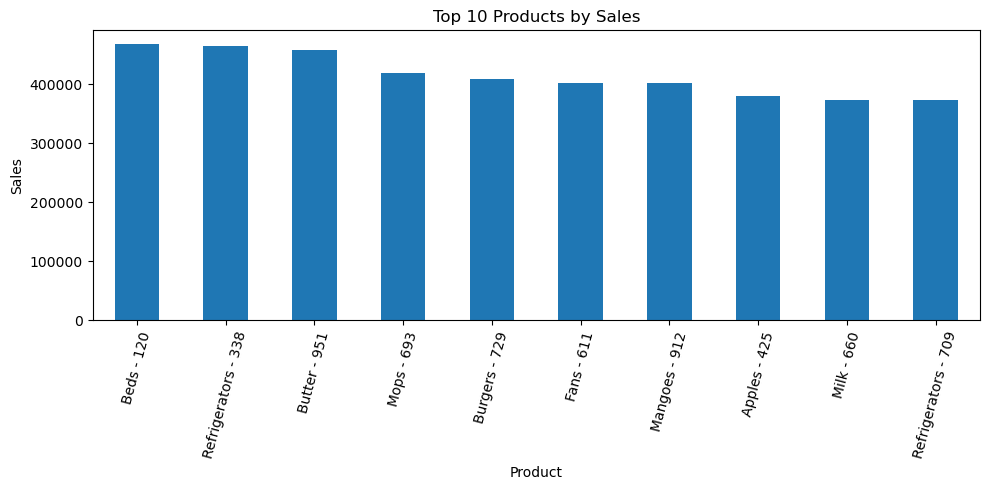

In [26]:
top_products.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


## 14. Customer sales

Find the customers who generated the highest sales.

In [27]:
customer_sales = (
    df.groupby("Customer Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

customer_sales.head(10)


Customer Name
Michael        58499915.92
James          39171310.28
David          38902696.83
Jennifer       38093682.26
Christopher    35774989.50
John           34964016.09
Robert         34606925.16
William        24507201.77
Matthew        24489941.53
Jessica        24387119.17
Name: Sales, dtype: float64

## 15. Number of orders per customer

Count each customer's unique orders. This gives a simple view of repeat purchasing.

In [28]:
customer_orders = df.groupby("Customer Name")["Order ID"].nunique()

customer_orders.sort_values(ascending=False).head(10)


Customer Name
Michael        2345
David          1563
James          1522
Jennifer       1472
Christopher    1438
John           1420
Robert         1366
Matthew         982
Jessica         970
Daniel          968
Name: Order ID, dtype: int64

## 16. Discount and profit

Compare total profit for each discount value.

In [29]:
discount_profit = df.groupby("Discount")["Profit"].sum().reset_index()

discount_profit


,Discount,Profit
0,0.00,4835681.61
1,0.01,9853711.22
2,0.02,9626416.42
3,0.03,9035406.79
4,0.04,9452635.90
5,0.05,9671925.28
6,0.06,9300202.49
7,0.07,9285910.23
8,0.08,9314161.82
9,0.09,8974797.98


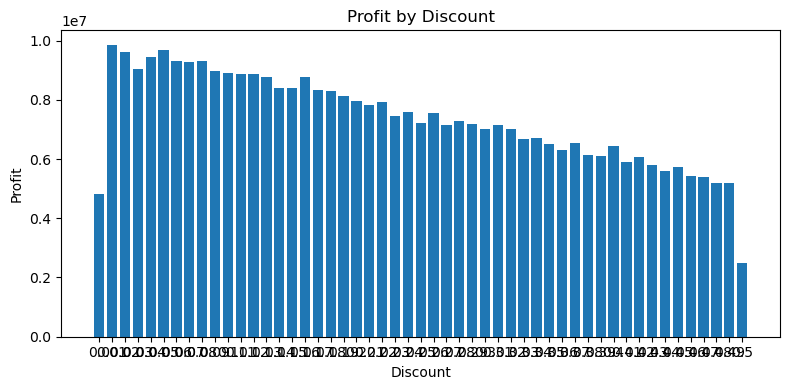

In [30]:
plt.figure(figsize=(8, 4))
plt.bar(discount_profit["Discount"].astype(str), discount_profit["Profit"])
plt.title("Profit by Discount")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()


## 17. Shipping time

If the dataset contains both `Order Date` and `Ship Date`, calculate how many days each order took to ship.

In [31]:
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

df[["Order Date", "Ship Date", "Shipping Days"]].head()


,Order Date,Ship Date,Shipping Days
0,2020-04-13,2020-04-18,5
1,2021-01-08,2021-01-11,3
2,2020-08-11,2020-08-16,5
3,2021-10-10,2021-10-16,6
4,2019-01-22,2019-01-25,3


In [32]:
print("Average shipping days:", round(df["Shipping Days"].mean(), 2))


Average shipping days: 3.99


## 18. Summary of findings

- Which year had the highest sales?
- Which category had the highest sales?
- Which category had the highest profit?
- Which products generated the most sales?
- Do higher discounts appear alongside lower profit?
- What is the average shipping time?


## 19. Conclusion

This project uses basic data analysis to explore retail sales performance, customer purchasing, product performance, discounts, and shipping.


